<a href="https://colab.research.google.com/github/shravya25-git/ML-LAB/blob/main/lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

In [ ]:
data = pd.read_csv("student_data.csv")
print(data)
print(data.head())
print(data.shape)



   Age  StudyHours  Attendence  PreviousMarks  AssignmentScore Result
0   18         NaN        75.0           55.0               68   Pass
1   19         4.0        82.0           61.0               75   Pass
2   20         1.5         NaN           21.0               38   Fail
3   21         3.5        68.0           49.0               72   Pass
4   19         2.0        51.0           35.0               44   Fail
5   22         5.0        91.0           78.0               88   Pass
6   20         3.0        73.0            NaN               69   Pass
7   18         1.0        35.0           28.0               31   Fail
8   23         4.5        86.0           81.0               92   Pass
9   21         2.5        59.0           42.0               50    NaN
   Age  StudyHours  Attendence  PreviousMarks  AssignmentScore Result
0   18         NaN        75.0           55.0               68   Pass
1   19         4.0        82.0           61.0               75   Pass
2   20         1.5  

In [ ]:
print(data.dtypes)
print(data.describe())
print(data.isnull().sum())

print(data.duplicated().sum())

Age                  int64
StudyHours         float64
Attendence         float64
PreviousMarks      float64
AssignmentScore      int64
Result              object
dtype: object
            Age  StudyHours  Attendence  PreviousMarks  AssignmentScore
count  10.00000    9.000000    9.000000       9.000000        10.000000
mean   20.10000    3.000000   68.888889      50.000000        62.700000
std     1.66333    1.369306   17.940488      20.934421        20.896837
min    18.00000    1.000000   35.000000      21.000000        31.000000
25%    19.00000    2.000000   59.000000      35.000000        45.500000
50%    20.00000    3.000000   73.000000      49.000000        68.500000
75%    21.00000    4.000000   82.000000      61.000000        74.250000
max    23.00000    5.000000   91.000000      81.000000        92.000000
Age                0
StudyHours         1
Attendence         1
PreviousMarks      1
AssignmentScore    0
Result             1
dtype: int64
0


In [ ]:
data["StudyHours"] = data ["StudyHours"].fillna(data["StudyHours"].mean())
data["Attendence"] = data ["Attendence"].fillna(data["Attendence"].mean())
data["PreviousMarks"]= data ["PreviousMarks"].fillna(data["PreviousMarks"].mean())
print(data.isnull().sum())

Age                0
StudyHours         0
Attendence         0
PreviousMarks      0
AssignmentScore    0
Result             1
dtype: int64


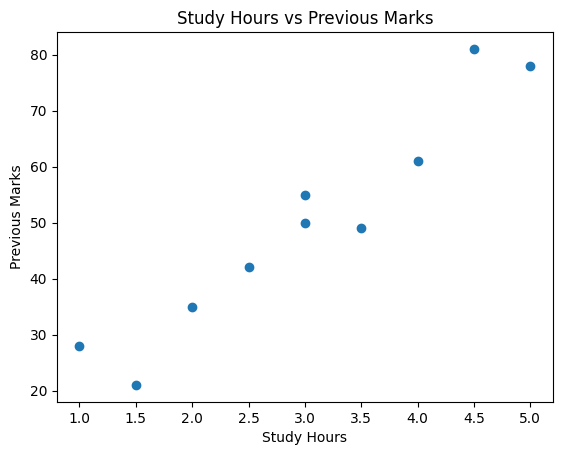

In [ ]:
plt.scatter(data["StudyHours"],data["PreviousMarks"])
plt.xlabel("Study Hours")
plt.ylabel("Previous Marks")
plt.title("Study Hours vs Previous Marks")
plt.show()

In [ ]:
data["PerformanceScore"]=(
    0.4*data["PreviousMarks"] + 0.3 * data["Attendence"] + 0.3 * data ["AssignmentScore"]
)
print(data.head())

   Age  StudyHours  Attendence  PreviousMarks  AssignmentScore Result  \
0   18         3.0   75.000000           55.0               68   Pass   
1   19         4.0   82.000000           61.0               75   Pass   
2   20         1.5   68.888889           21.0               38   Fail   
3   21         3.5   68.000000           49.0               72   Pass   
4   19         2.0   51.000000           35.0               44   Fail   

   PerformanceScore  
0         64.900000  
1         71.500000  
2         40.466667  
3         61.600000  
4         42.500000  


In [ ]:
x=data[
    ["StudyHours","Attendence",
     "PreviousMarks","AssignmentScore",
     "PerformanceScore"]
]
y=data["Result"]

In [ ]:
data

,Age,StudyHours,Attendence,PreviousMarks,AssignmentScore,Result,PerformanceScore
0,18,3.0,75.000000,55.0,68,Pass,64.900000
1,19,4.0,82.000000,61.0,75,Pass,71.500000
2,20,1.5,68.888889,21.0,38,Fail,40.466667
3,21,3.5,68.000000,49.0,72,Pass,61.600000
4,19,2.0,51.000000,35.0,44,Fail,42.500000
5,22,5.0,91.000000,78.0,88,Pass,84.900000
6,20,3.0,73.000000,50.0,69,Pass,62.600000
7,18,1.0,35.000000,28.0,31,Fail,31.000000
8,23,4.5,86.000000,81.0,92,Pass,85.800000
9,21,2.5,59.000000,42.0,50,NaN,49.500000


In [ ]:
y=y.map({"Fail":0,"Pass":1})
print(y)

X=data[["StudyHours","Attendence",
     "AssignmentScore",
     "PerformanceScore"]]

0   NaN
1   NaN
2   NaN
3   NaN
4   NaN
5   NaN
6   NaN
7   NaN
8   NaN
9   NaN
Name: Result, dtype: float64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    test_size=0.2,
    random_state=42
)
print(X_train,y_train)

   StudyHours  Attendence  AssignmentScore  PerformanceScore
5         5.0   91.000000               88         84.900000
0         3.0   75.000000               68         64.900000
7         1.0   35.000000               31         31.000000
2         1.5   68.888889               38         40.466667
9         2.5   59.000000               50         49.500000
4         2.0   51.000000               44         42.500000
3         3.5   68.000000               72         61.600000
6         3.0   73.000000               69         62.600000 5   NaN
0   NaN
7   NaN
2   NaN
9   NaN
4   NaN
3   NaN
6   NaN
Name: Result, dtype: float64


In [ ]:
model=DecisionTreeClassifier(
max_depth=3,
random_state=42
)

In [ ]:
model.fit(X_train,y_train)

ValueError: Input y contains NaN.

In [ ]:
y_pred = model.predict(X_test)
print(y_pred)

result = pd.DataFrame({"Actual":y_test,"Predicted":y_pred})
print(result)

NotFittedError: This DecisionTreeClassifier instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.